In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from getdist import loadMCSamples, plots, MCSamples, paramnames
import copy
import pandas as pd

if not os.path.exists('figs'):
    os.makedirs('figs')

%matplotlib inline

In [2]:
def CombineSamples(samps1, samps2, sample_weights=(1, 1)):
    """
    Make a new `MCSamples` instance by combining samples from samps1 and samps2 for parameters which are in common.
    By default, they are weighted so that the probability mass of each set of samples is the same,
    independent of tha actual sample sizes. The sample_weights parameter can be adjusted to change the
    relative weighting.
    Note: This function has been ripped off from the source code of getdist and modified, as their function just doesn't work!!!

    Params:
    @param samps1, samps2: `MCSamples` instances to merge
    @param sample_weights: relative weights for combining the samples. Set to None to just directly append samples.
    Returns: a new `MCSamples` instance with the combined samples
    """

    params = samps1.paramNames
    # params.names = [ParamInfo(name=p.name, label=p.label, derived=p.isDerived) for p in samps2.paramNames.names if p.name in samps1.paramNames.list()]
    if samps1.loglikes is not None and samps2.loglikes is not None:
        loglikes = np.concatenate([samps1.loglikes, samps2.loglikes])
    else:
        loglikes = None
    if sample_weights is None:
        fac = 1
        sample_weights = (1, 1)
    else:
        fac = np.sum(samps1.weights) / np.sum(samps2.weights)
    weights = np.concatenate([samps1.weights * sample_weights[0], samps2.weights * sample_weights[1] * fac])
    # p1 = samps1.getParams()
    # p2 = samps2.getParams()
    samples = np.vstack([samps1.samples,samps2.samples]) # np.array([np.concatenate([getattr(p1, name), getattr(p2, name)]) for name in params.list()]).T
    samps = MCSamples(
        samples=samples,
        weights=weights,
        loglikes=loglikes,
        paramNamesFile=params,
        ignore_rows=0,
        ranges=samps1.ranges,
        settings=copy.deepcopy(samps1.ini.params),
    )
    return samps

In [3]:
# Define root directory (dir where chains are stored)
root_dir = './JBP_DESI_cmprsdCMB_SNe_outputs'

# Define a list of config files
config_files = ['JBP_DR2_cmprsdCMB_chain','JBP_DR2_cmprsdCMB_PantheonPlus_chain','JBP_DR2_cmprsdCMB_Union3_chain','JBP_DR2_cmprsdCMB_DESY5_chain']

# Define the fraction of samples to ignore as burn-in (e.g., 30%)
burnin_fraction = 0.3

# Define the number of chains in one file
num_chains = 4

# Define a list to collect the combined samples for all the config files
combined_samples_all_configs = []

# Iterate over the config files to load combined samples
for config_file in config_files:
    
    # Load the names of the root files for each config file in the directory
    job_roots = [f"{root_dir}/{config_file}{i}" for i in range(num_chains)]
    
    # Load the MCMC samples for the first root file
    combined_samples = loadMCSamples(job_roots[0], settings={'ignore_rows': burnin_fraction})
    
    for root in job_roots[1:]:
        # Load samples for each root file after the first root file
        samples = loadMCSamples(root, settings={'ignore_rows': burnin_fraction})
        
        # Use the CombineSamples to combine the samples extracted in the loop to the main MCsamples object
        combined_samples = CombineSamples(combined_samples,samples)

    # Append the final MCsamples object for the config file to the main list
    combined_samples_all_configs.append(combined_samples)

    # Print confirmation
    print(f"Loaded combined samples for config file: {config_file}")

combined_samples_all_configs

./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.1.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.10.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.11.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.12.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.13.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.14.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.15.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.16.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.2.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.3.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.4.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.5.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.6.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.7.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/JBP_DR2_cmprsdCMB_chain0.8.txt
./JBP_DESI_cmprsdCMB_SNe_outputs/

In [4]:
gr_statistic_vals = []
for config_file in config_files:    
    # Load the names of the root files for each config file in the directory
    job_roots = [f"{root_dir}/{config_file}{i}" for i in range(num_chains)]
    # Define a list to store all MCSamples objects
    config_separate_chains = []
    for root in job_roots:
        # Load samples for each root file
        samples = loadMCSamples(root, settings={'ignore_rows': burnin_fraction})
        # Append the samples to the separate chains list
        config_separate_chains.append(samples)
    gr_statistic = config_separate_chains[0].getGelmanRubin(chainlist=config_separate_chains)
    print(f'Gelman-Rubin statistic for {config_file}: {gr_statistic:.5f}\n')
    gr_statistic_vals.append(gr_statistic)

Gelman-Rubin statistic for JBP_DR2_cmprsdCMB_chain: 0.00066

Gelman-Rubin statistic for JBP_DR2_cmprsdCMB_PantheonPlus_chain: 0.00264

Gelman-Rubin statistic for JBP_DR2_cmprsdCMB_Union3_chain: 0.00160

Gelman-Rubin statistic for JBP_DR2_cmprsdCMB_DESY5_chain: 0.00137



In [5]:
tests_dict = {}
corr_len = []
ess = []
for config, combined_all in zip(config_files, combined_samples_all_configs):
    corr_len.append([combined_all.getCorrelationLength('w'),combined_all.getCorrelationLength('wa')])
    ess.append([combined_all.getEffectiveSamples('w'),combined_all.getEffectiveSamples('wa')])
tests_dict['Data'] = [config_file.replace('_','+')[4:-6] for config_file in config_files]
tests_dict['Gelman-Rubin statistic'] = gr_statistic_vals
tests_dict['Corr len (w)'] = [w_len[0] for w_len in corr_len]
tests_dict['Corr len (wa)'] = [wa_len[1] for wa_len in corr_len]
tests_dict['ESS (w)'] = [w_ess[0] for w_ess in ess]
tests_dict['ESS (wa)'] = [wa_ess[1] for wa_ess in ess]

In [6]:
tests_df = pd.DataFrame(tests_dict)
latex_table = tests_df.to_latex(index=False, escape=False)
caption = 'Table enlisting the results of the convergence tests performed for the JBP DE EoS on the samples with DR2 and SNe data with compressed CMB priors'
label = 'table:dr2_cmprsdcmb_test_results'
full_table = (
        "\\begin{table}[H]\n"
        "\\centering\n"
        f"{latex_table}\n"
        f"\\caption{{{caption}}}\n"
        f"\\label{{{label}}}\n"
        "\\end{table}"
    )

print(full_table)

\begin{table}[H]
\centering
\begin{tabular}{lrrrrr}
\toprule
Data & Gelman-Rubin statistic & Corr len (w) & Corr len (wa) & ESS (w) & ESS (wa) \\
\midrule
DR2+cmprsdCMB & 0.000661 & 97.464555 & 95.668415 & 12091.370083 & 12318.381113 \\
DR2+cmprsdCMB+PantheonPlus & 0.002644 & 39.331272 & 39.462190 & 19395.456983 & 19331.111524 \\
DR2+cmprsdCMB+Union3 & 0.001596 & 55.250055 & 55.358138 & 16498.807085 & 16466.594426 \\
DR2+cmprsdCMB+DESY5 & 0.001370 & 42.872861 & 43.040600 & 15395.846893 & 15335.845617 \\
\bottomrule
\end{tabular}

\caption{Table enlisting the results of the convergence tests performed for the JBP DE EoS on the samples with DR2 and SNe data with compressed CMB priors}
\label{table:dr2_cmprsdcmb_test_results}
\end{table}


In [7]:
param_vals = {}
w_vals = []
wa_vals = []
for config, combined_all in zip(config_files, combined_samples_all_configs):
    w_mean = combined_all.mean(['w'])[0]
    w_std = combined_all.std(['w'])[0]
    wa_mean = combined_all.mean(['wa'])[0]
    wa_std = combined_all.std(['wa'])[0]
    w_vals.append(f'${w_mean:.4f}\\pm{w_std:.4f}$')
    wa_vals.append(f'${wa_mean:.4f}\\pm{wa_std:.4f}$')
param_vals['Data'] = [config_file.replace('_','+')[:-6] for config_file in config_files]
param_vals['w'] = w_vals
param_vals['wa'] = wa_vals
param_df = pd.DataFrame(param_vals)
latex_table = param_df.to_latex(index=False, escape=False)
caption = 'Table of parameter values for the JBP DE EoS'
label = 'tab:param_vals'
full_table = (
        "\\begin{table}[H]\n"
        "\\centering\n"
        f"{latex_table}\n"
        f"\\caption{{{caption}}}\n"
        f"\\label{{{label}}}\n"
        "\\end{table}"
    )
print(full_table)

\begin{table}[H]
\centering
\begin{tabular}{lll}
\toprule
Data & w & wa \\
\midrule
JBP+DR2+cmprsdCMB & $-0.6363\pm0.2009$ & $-1.8671\pm0.9332$ \\
JBP+DR2+cmprsdCMB+PantheonPlus & $-0.8250\pm0.0784$ & $-0.9747\pm0.4782$ \\
JBP+DR2+cmprsdCMB+Union3 & $-0.5936\pm0.1068$ & $-2.0866\pm0.5634$ \\
JBP+DR2+cmprsdCMB+DESY5 & $-0.6810\pm0.0826$ & $-1.7038\pm0.5039$ \\
\bottomrule
\end{tabular}

\caption{Table of parameter values for the JBP DE EoS}
\label{tab:param_vals}
\end{table}


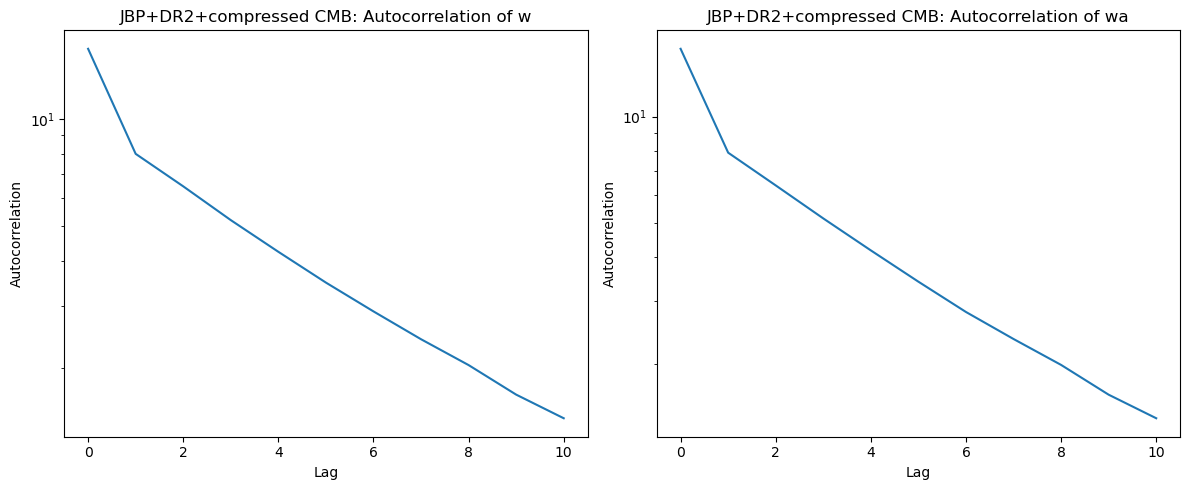

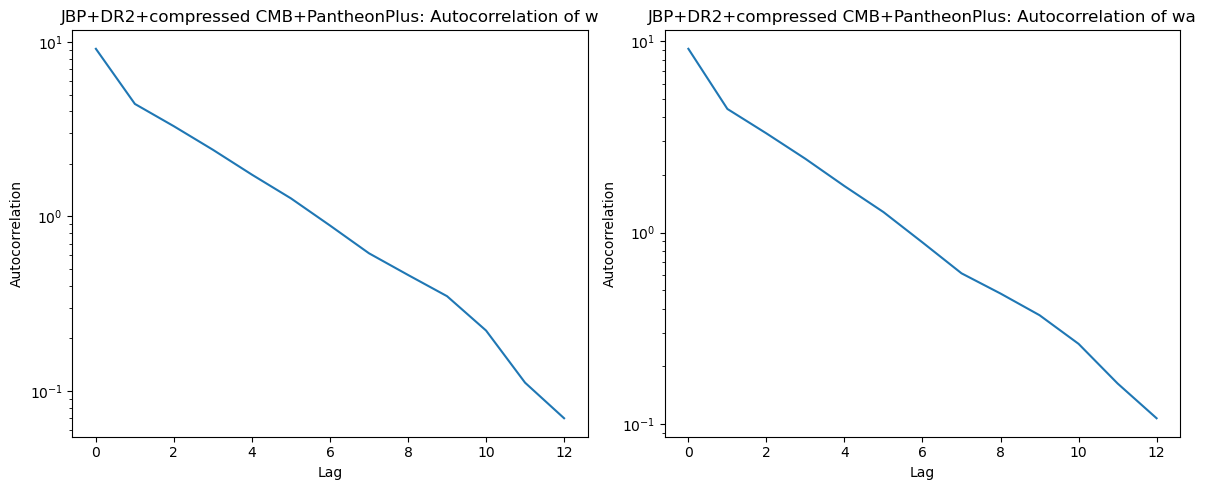

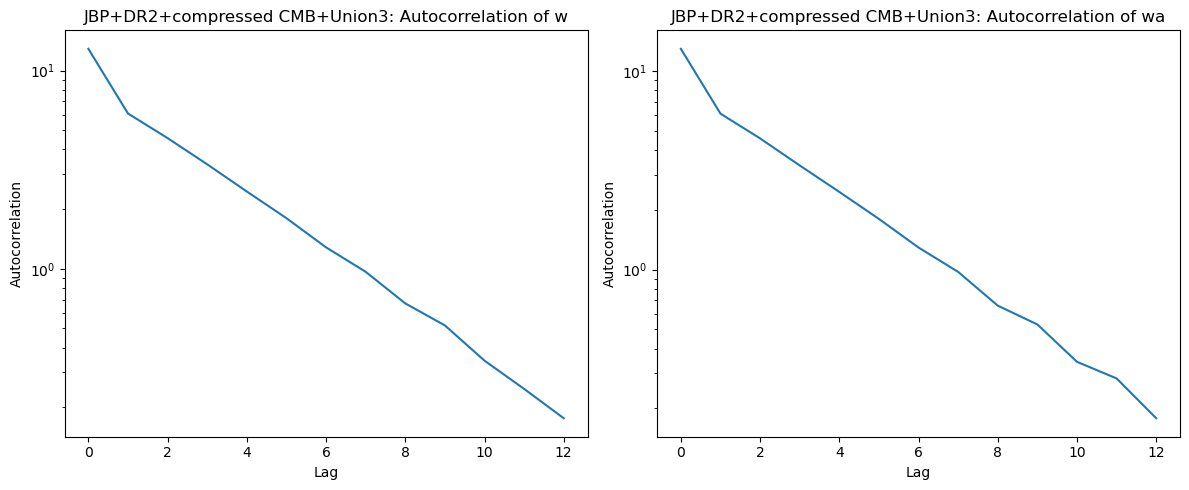

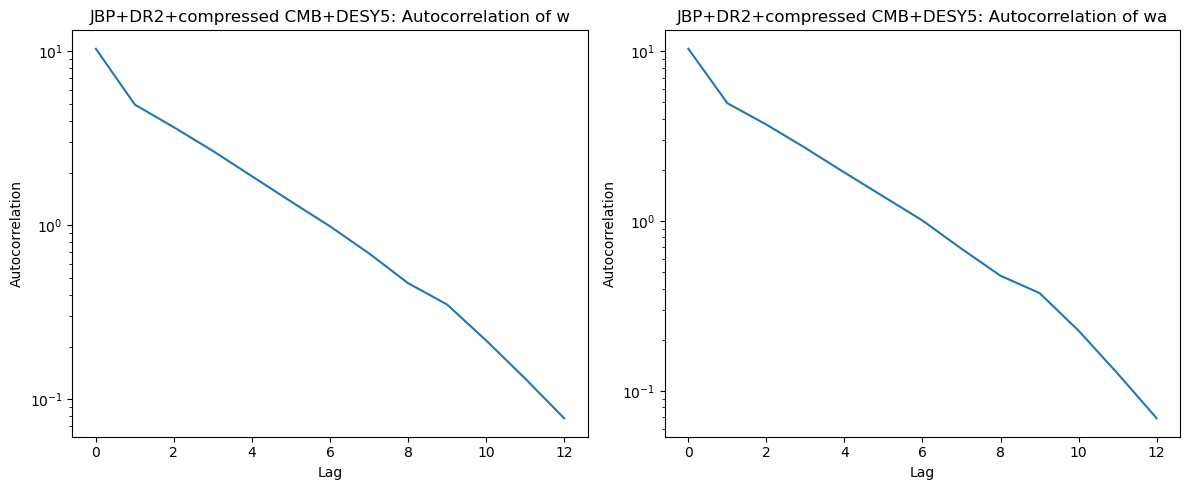

In [8]:
for config, combined_all in zip(config_files, combined_samples_all_configs):
    autocorr_w = combined_all.getAutocorrelation('w')
    autocorr_wa = combined_all.getAutocorrelation('wa')
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(autocorr_w)
    plt.title(f"{config[:-6].replace('_','+').replace('cmprsd','compressed ')}: Autocorrelation of w")
    plt.xlabel('Lag')
    plt.ylabel('Autocorrelation')
    plt.yscale('log')

    plt.subplot(1, 2, 2)
    plt.plot(autocorr_wa)
    plt.title(f"{config[:-6].replace('_','+').replace('cmprsd','compressed ')}: Autocorrelation of wa")
    plt.xlabel('Lag')
    plt.ylabel('Autocorrelation')
    plt.yscale('log')
    plt.tight_layout()

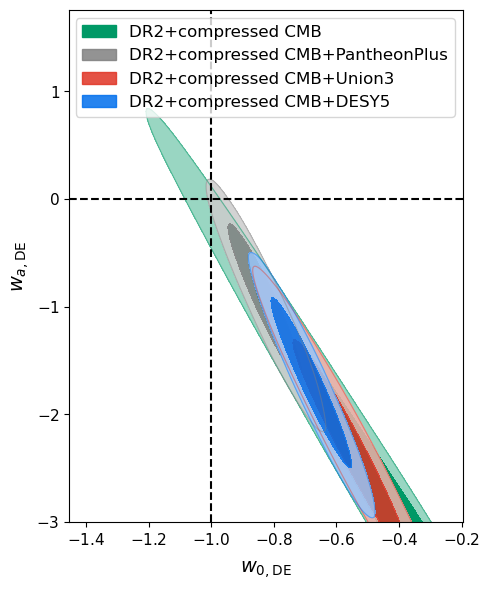

In [9]:
# Get a plotter instance for a single plot
g = plots.get_single_plotter(width_inch=5,ratio=1.2)

# Plot the 2D contours for 'x0' vs 'x1' from both sample sets.
# 'filled=True' creates filled contours. You can also use 'shaded=True'.
g.plot_2d(combined_samples_all_configs,"w","wa",filled=True,)

custom_legend_labels_single = ["DR2+compressed CMB", "DR2+compressed CMB+PantheonPlus", "DR2+compressed CMB+Union3", "DR2+compressed CMB+DESY5"]

# Add a vertical line at x = 0.5
g.add_x_marker(-1.0, color="black", ls="--", lw=1.5)

# Add a horizontal line at y = -0.2
g.add_y_marker(0.0, color="black", ls="--", lw=1.5)

g.add_legend(custom_legend_labels_single, colored_text=False, legend_loc='upper right')

g.export("figs/JBP_DR2_cmprsdCMB_SNe_chain_analysis.png")

JBP_DR2_cmprsdCMB_chain: 174101
JBP_DR2_cmprsdCMB_PantheonPlus_chain: 154425
JBP_DR2_cmprsdCMB_Union3_chain: 165058
JBP_DR2_cmprsdCMB_DESY5_chain: 132573


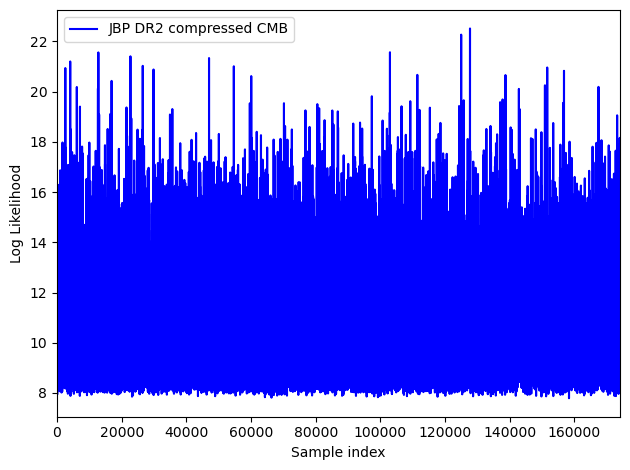

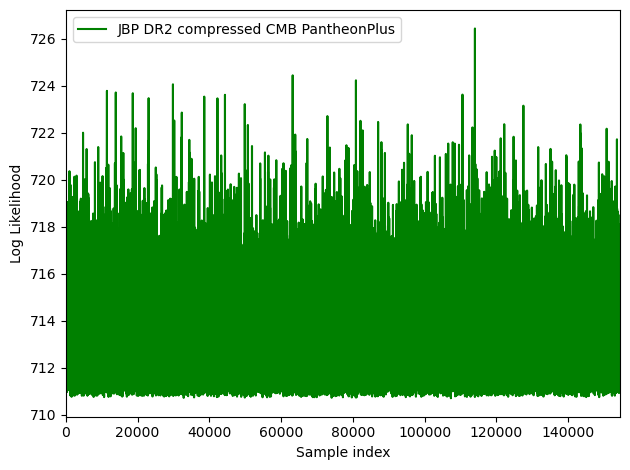

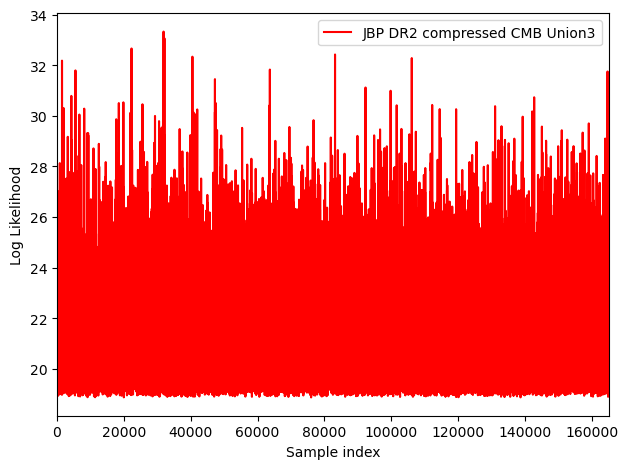

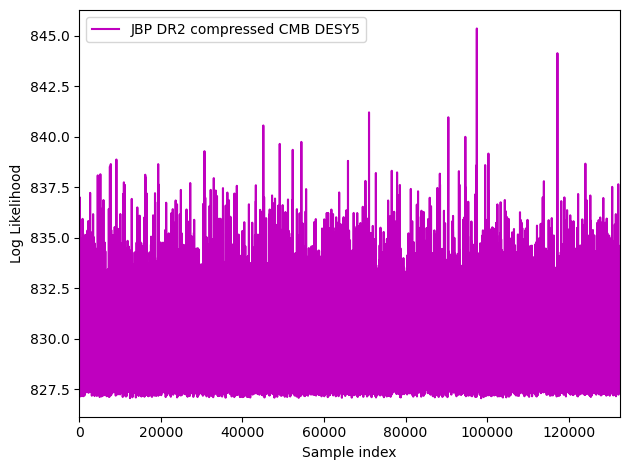

In [10]:
for config_file, combined_sample, color in zip(config_files, combined_samples_all_configs,['b','g','r','m']):
    plt.figure()
    loglikes = combined_sample.loglikes  # Array of -log(likelihood)
    # Usually loglikes are stored as -log(L)
    # If you want log likelihood (not negative), flip sign
    plt.plot(loglikes, '-'+color, label=f"{config_file.replace('_',' ').replace('cmprsd','compressed ')[:-6]}")
    plt.xlabel("Sample index")
    plt.ylabel("Log Likelihood")
    plt.xlim(0,len(loglikes))
    # plt.title("")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'figs/{config_file[:-6]}_traceplot.png')
    print(f'{config_file}: {len(loglikes)}')

Scratch code region: **DO NOT RUN!**\
ONLY TO BE USED AS A REFERENCE FOR FUNCTIONS!

In [ ]:
# Scratch code region: DO NOT RUN!
# ONLY TO BE USED AS A REFERENCE FOR FUNCTIONS!

# Load MCMC samples from a root chain file
samps = loadMCSamples(root)

# Remove burn in from the samples
samps.removeBurnFraction(0.3)

# Get parameter names in a list
samps.paramNames.list()

# Get parameter samples
samps.samples

# Get parameter weights
samps.weights

# Get parameter log-likelihoods
samps.loglikes

# User-defined function: Combine two chains (refer to the above cells for function description)
CombineSamples(samps1, samps2)

# Compute the mean and standard deviation of the selected parameters
samps.mean(['w','wa']), samps.std(['w','wa'])

In [19]:
combined_samples_all_configs[0].paramNames.list()

['ombh2',
 'omch2',
 'theta_MC_100',
 'w',
 'wa',
 'omega_bc',
 'H0',
 'chi2__BAO',
 'chi2',
 'chi2__compressed_cmb',
 'chi2__bao.desi_dr2']

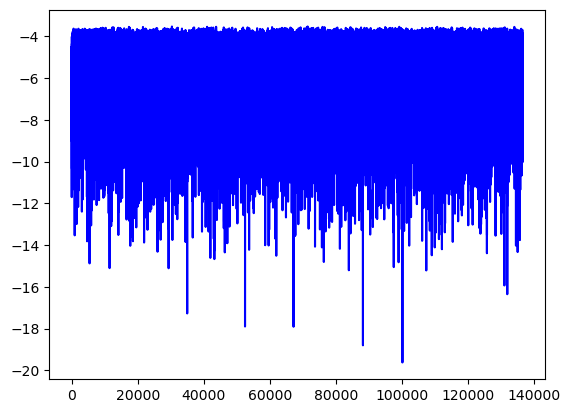

In [21]:
plt.plot(-0.5*combined_samples_all_configs[0]['chi2'],'-b')